# Resume Classification — Project 691

**Objective:** Build a text classification pipeline that reads resumes (PDF/DOC/DOCX),
extracts and cleans the text, and prepares it for a machine learning model that predicts
the job category (e.g. React Developer, SQL Developer, Workday, Peoplesoft) from resume
content.

**Scope of this notebook:** dataset collection, text extraction, de-duplication, EDA,
and text preprocessing, ending with a cleaned dataset ready for modeling.


# Step 1: Import Required Libraries

- **os** → work with folders and files.
- **re, string** → text cleaning with regular expressions.
- **numpy, pandas** → numerical computation and data manipulation.
- **matplotlib, seaborn** → visualization.
- **pdfplumber** → extract text from PDF resumes.
- **python-docx** → extract text from `.docx` resumes.
- **subprocess, tempfile, shutil** → drive LibreOffice in headless mode, used to convert
  `.doc` files to text and as a fallback for `.docx` files that don't open normally.
- **nltk** → stopword removal and stemming.


In [1]:
import os
import re
import string
import subprocess
import tempfile
import warnings

warnings.filterwarnings("ignore")

# Data Manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Resume Text Extraction
import pdfplumber
from docx import Document

# Natural Language Processing
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer


In [2]:
# No additional installs needed here — LibreOffice (used for .doc extraction and
# as a .docx fallback) is called directly via subprocess in Step 3.


In [3]:
nltk.download("stopwords")
nltk.download("punkt")


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Lingaraj\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Lingaraj\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

# Step 2: Dataset Overview

Before extracting resume text, it's important to understand the structure of the dataset.

The resumes are organized into folders, where each folder represents a job category. This step catalogs every file (category, filename, extension, size) so we can spot issues — like folder-naming inconsistencies or unexpected file types — before extraction.


### Category Label Normalization

Some dataset folders use slightly different names for the same job category (e.g. `Peoplesoft` vs `Peoplesoft Resume`). This mapping standardizes those labels **before** they're used anywhere else in the notebook, so the same class doesn't get split into two.


In [4]:
# Normalize category names — some folders are duplicate/near-duplicate labels
# for the same class (e.g. "Peoplesoft" vs "Peoplesoft Resume").
CATEGORY_MAP = {
    "Peoplesoft": "Peoplesoft Resume",
    "Peoplesoft Resume": "Peoplesoft Resume",
    "React Developer": "React Developer",
    "SQL Developer": "SQL Developer",
    "workday": "workday",
}

def normalize_category(folder_name):
    return CATEGORY_MAP.get(folder_name, folder_name)


In [5]:
# Dataset Path 
ROOT =  r"C:\Users\Lingaraj\Desktop\RESUME_CLASSIFICATION\P691 Dataset\P637 Dataset\Resumes_Docx"

rows = []

for category in os.listdir(ROOT):

    category_path = os.path.join(ROOT, category)

    if os.path.isdir(category_path):

        for file in os.listdir(category_path):

            # Ignore temporary MS Word lock files (start with ~$) — these aren't real resumes
            if file.startswith("~$"):
                continue

            filepath = os.path.join(category_path, file)

            rows.append({
                "Category": normalize_category(category),
                "File_Name": file,
                "Extension": os.path.splitext(file)[1].lower(),
                "Size_KB": round(os.path.getsize(filepath) / 1024, 2)
            })

df = pd.DataFrame(rows)
df


,Category,File_Name,Extension,Size_KB
0,Peoplesoft Resume,Peoplesoft Admin_G Ananda Rayudu.docx,.docx,63.00
1,Peoplesoft Resume,Peoplesoft Admin_AnubhavSingh.docx,.docx,231.96
2,Peoplesoft Resume,Peoplesoft Admin_G Ananda Rayudu.doc,.doc,63.00
3,Peoplesoft Resume,Peoplesoft Admin_Gangareddy.doc,.doc,48.00
4,Peoplesoft Resume,Peoplesoft Admin_Murali.docx,.docx,32.41
...,...,...,...,...
75,workday,Sri Krishna S_Hexaware.doc,.doc,67.50
76,workday,Srikanth-Hexaware.docx,.docx,39.58
77,workday,SSKumar_Hexaware.docx,.docx,35.49
78,workday,Venkateswarlu B_Hexaware.doc,.doc,96.50


In [6]:
df.duplicated().sum()


np.int64(0)

In [7]:
df.tail()


,Category,File_Name,Extension,Size_KB
75,workday,Sri Krishna S_Hexaware.doc,.doc,67.50
76,workday,Srikanth-Hexaware.docx,.docx,39.58
77,workday,SSKumar_Hexaware.docx,.docx,35.49
78,workday,Venkateswarlu B_Hexaware.doc,.doc,96.50
79,workday,Vinay Kumar_Hexaware.docx,.docx,48.17


In [8]:
df.shape


(80, 4)

In [9]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Category   80 non-null     object 
 1   File_Name  80 non-null     object 
 2   Extension  80 non-null     object 
 3   Size_KB    80 non-null     float64
dtypes: float64(1), object(3)
memory usage: 2.6+ KB


In [10]:
df["Category"].value_counts()


Category
React Developer      24
Peoplesoft Resume    21
workday              21
SQL Developer        14
Name: count, dtype: int64

In [11]:
df["Extension"].value_counts()


Extension
.docx    53
.doc     26
.pdf      1
Name: count, dtype: int64

In [12]:
df.describe(include="all")


,Category,File_Name,Extension,Size_KB
count,80,80,80,80.000000
unique,4,80,3,NaN
top,React Developer,Peoplesoft Admin_G Ananda Rayudu.docx,.docx,NaN
freq,24,1,53,NaN
mean,NaN,NaN,NaN,72.671625
std,NaN,NaN,NaN,110.281438
min,NaN,NaN,NaN,10.240000
25%,NaN,NaN,NaN,22.597500
50%,NaN,NaN,NaN,38.645000
75%,NaN,NaN,NaN,71.500000


In [13]:
# Note: this checks for duplicate rows at the FILE-LISTING level (name/extension/size).
# It will not catch the same resume saved twice in different formats (.doc + .docx) —
# that is checked later, after the text itself has been extracted.
df.duplicated().sum()


np.int64(0)

In [14]:
df.sample(5, random_state=42)


,Category,File_Name,Extension,Size_KB
30,React Developer,React Developer_Thirupathiamma.docx,.docx,24.84
0,Peoplesoft Resume,Peoplesoft Admin_G Ananda Rayudu.docx,.docx,63.00
22,React Developer,Internship_Susovan Bag_Musquare Technologies.docx,.docx,14.61
31,React Developer,React Developer_Vinay Reddy.doc,.doc,35.50
18,Peoplesoft Resume,Peoplesoft FSCM_R Ahmed.doc,.doc,67.00


# Step 3: Resume Text Extraction

Resumes are stored as `.pdf`, `.docx`, and `.doc`. Machine learning algorithms can't process these formats directly, so the text content is extracted from each file and paired with its job category (from the folder it came from).

Three extraction paths are used depending on file type, with a fallback for `.docx` files that fail to open normally:
- **`.pdf`** → `pdfplumber`
- **`.docx`** → `python-docx` (primary), LibreOffice conversion (fallback for malformed files)
- **`.doc`** → LibreOffice headless conversion


In [15]:
# Function to extract text from PDF
def extract_pdf_text(file_path):

    text = ""

    with pdfplumber.open(file_path) as pdf:

        for page in pdf.pages:

            page_text = page.extract_text()

            if page_text:
                text += page_text + "\n"

    return text


# Function to extract text from DOCX (primary method)
def extract_docx_text(file_path):

    doc = Document(file_path)

    text = "\n".join([para.text for para in doc.paragraphs])

    return text


# Locating LibreOffice on this machine. Installing LibreOffice doesn't always add it
# to the system PATH (especially on Windows), so instead of calling "soffice" and
# hoping it resolves, this checks PATH first and then falls back to the standard
# install locations for each OS.

import shutil

def _find_soffice():
    found = shutil.which("soffice") or shutil.which("soffice.exe")
    if found:
        return found

    candidate_paths = [
        r"C:\Program Files\LibreOffice\program\soffice.exe",
        r"C:\Program Files (x86)\LibreOffice\program\soffice.exe",
        "/Applications/LibreOffice.app/Contents/MacOS/soffice",
        "/usr/bin/soffice",
        "/usr/local/bin/soffice",
    ]
    for path in candidate_paths:
        if os.path.exists(path):
            return path

    return None

SOFFICE_PATH = _find_soffice()

if SOFFICE_PATH is None:
    print("WARNING: LibreOffice ('soffice') was not found on this machine.")
    print("All .doc files (and any malformed .docx files) will fail to extract until this is fixed.")
    print("Fix: install LibreOffice from https://www.libreoffice.org/download/download-freedom/")
    print("If it's already installed, find soffice.exe and add its full path to")
    print("'candidate_paths' in the _find_soffice() function above, then re-run this cell.")
else:
    print(f"LibreOffice found at: {SOFFICE_PATH}")


# Fallback extractor for DOCX files that fail with python-docx (handles corrupted
# or non-standard docx files) — uses the same LibreOffice engine as the .doc extractor.
def extract_docx_text_fallback(file_path):
    return _extract_via_libreoffice(file_path)


# Function to extract text from legacy binary .doc files using LibreOffice headless
# conversion — works on any platform LibreOffice is installed on, no MS Office needed.
def extract_doc_text(file_path):
    return _extract_via_libreoffice(file_path)


def _extract_via_libreoffice(file_path):
    """Converts a .doc/.docx file to plain text using LibreOffice headless mode,
    then reads the result. Each file gets its own temp output folder so that two
    files with the same base name never overwrite each other's converted output."""
    if SOFFICE_PATH is None:
        raise RuntimeError(
            "LibreOffice not found on this machine. See the warning printed above this "
            "cell's output for how to fix it."
        )
    with tempfile.TemporaryDirectory() as tmpdir:
        result = subprocess.run(
            [SOFFICE_PATH, "--headless", "--convert-to", "txt:Text", "--outdir", tmpdir, file_path],
            capture_output=True, text=True, timeout=60
        )
        base = os.path.splitext(os.path.basename(file_path))[0]
        txt_path = os.path.join(tmpdir, base + ".txt")
        if not os.path.exists(txt_path):
            raise RuntimeError(f"LibreOffice conversion failed: {result.stderr.strip()}")
        with open(txt_path, encoding="utf-8", errors="ignore") as f:
            return f.read()


LibreOffice found at: C:\Program Files\LibreOffice\program\soffice.exe


In [16]:
resume_data = []

failed_files = []

supported_files = (".docx", ".pdf", ".doc")

for category in os.listdir(ROOT):

    category_path = os.path.join(ROOT, category)

    if not os.path.isdir(category_path):
        continue

    for file in os.listdir(category_path):

        # Ignore temporary Word lock files
        if file.startswith("~$"):
            continue

        extension = os.path.splitext(file)[1].lower()

        if extension not in supported_files:
            continue

        filepath = os.path.join(category_path, file)

        # Records which extraction method actually worked for each file — useful
        # for spotting files that needed the fallback route (usually a sign the
        # file is internally malformed despite its extension).
        extraction_method = None

        try:

            if extension == ".pdf":
                text = extract_pdf_text(filepath)
                extraction_method = "pdfplumber"

            elif extension == ".doc":
                text = extract_doc_text(filepath)
                extraction_method = "libreoffice (.doc)"

            else:
                try:
                    text = extract_docx_text(filepath)
                    extraction_method = "python-docx (primary)"
                except Exception:
                    text = extract_docx_text_fallback(filepath)
                    extraction_method = "libreoffice (.docx fallback)"

            resume_data.append({
                "File_Name": file,
                "Category": normalize_category(category),
                "Resume": text,
                "Extraction_Method": extraction_method
            })

        except Exception as e:

            failed_files.append({
                "File_Name": file,
                "Reason": str(e)
            })


In [17]:
resume_df = pd.DataFrame(resume_data)

print("Shape before de-duplication:", resume_df.shape)
resume_df.head()


Shape before de-duplication: (80, 4)


,File_Name,Category,Resume,Extraction_Method
0,Peoplesoft Admin_G Ananda Rayudu.docx,Peoplesoft Resume,\n\n\n\n\n\n\t\n\nProfile Summary:\t\t\t\t\t\t...,libreoffice (.docx fallback)
1,Peoplesoft Admin_AnubhavSingh.docx,Peoplesoft Resume,Anubhav Kumar Singh\t\t\n\n To work in a gl...,python-docx (primary)
2,Peoplesoft Admin_G Ananda Rayudu.doc,Peoplesoft Resume,\n\n\n\n\n\n\t\n\nProfile Summary:\t\t\t\t\t\t...,libreoffice (.doc)
3,Peoplesoft Admin_Gangareddy.doc,Peoplesoft Resume,PeopleSoft Database Administrator\n ...,libreoffice (.doc)
4,Peoplesoft Admin_Murali.docx,Peoplesoft Resume,Murali\n\nExperience Summary \n\nI have 6 year...,python-docx (primary)


In [18]:
# Which files needed the fallback extractor (i.e. python-docx couldn't open them
# directly)? Usually means the file is internally malformed despite its extension.
fallback_used = resume_df[resume_df["Extraction_Method"].str.contains("fallback", na=False)]
print(f"{len(fallback_used)} file(s) needed the fallback extractor:")
fallback_used[["Category", "File_Name", "Extraction_Method"]]


1 file(s) needed the fallback extractor:


,Category,File_Name,Extraction_Method
0,Peoplesoft Resume,Peoplesoft Admin_G Ananda Rayudu.docx,libreoffice (.docx fallback)


### Remove duplicate resumes — pass 1: same resume saved as both `.doc` and `.docx`

Some resumes exist twice in the dataset — once as `.doc` and once as `.docx` — which would
otherwise count the same person's resume twice and inflate certain categories. This keeps a
single copy per person (per category + filename), preferring the `.docx`/`.pdf` version since
it tends to extract more cleanly than the legacy `.doc` route.

A second pass (further below) catches resumes saved under **completely different filenames**,
which this filename-based pass can't catch.


In [19]:
# Pass 1: de-duplicate by (Category, Base_Name) — catches the same resume saved as
# both .doc and .docx under the same filename.
resume_df["Base_Name"] = resume_df["File_Name"].apply(
    lambda x: os.path.splitext(x)[0].strip().lower()
)

resume_df["Ext_Priority"] = resume_df["File_Name"].apply(
    lambda x: 0 if os.path.splitext(x)[1].lower() in (".docx", ".pdf") else 1
)

resume_df = (
    resume_df.sort_values("Ext_Priority")
              .drop_duplicates(subset=["Category", "Base_Name"], keep="first")
              .drop(columns=["Base_Name", "Ext_Priority"])
              .reset_index(drop=True)
)

print("Shape after pass 1 (filename-based) de-duplication:", resume_df.shape)
resume_df.head()


Shape after pass 1 (filename-based) de-duplication: (79, 4)


,File_Name,Category,Resume,Extraction_Method
0,Peoplesoft Admin_G Ananda Rayudu.docx,Peoplesoft Resume,\n\n\n\n\n\n\t\n\nProfile Summary:\t\t\t\t\t\t...,libreoffice (.docx fallback)
1,React JS Developer_Venkatalakshmi (1)-converte...,React Developer,Venkatalakshmi Pedireddy\nSoftware Developer\n...,python-docx (primary)
2,Reactjs Developer_kambala sai surendra_Musquar...,React Developer,KAMBALA SAI SURENDRA \n \n\tMandepeta \t \n ...,python-docx (primary)
3,Reactjs Developer_M Lokesh Babu_Musquare Techn...,React Developer,MAREEDU LOKESH BABU\nPROFESSIONAL OVERVIEW\n ...,python-docx (primary)
4,Reactjs Developer_MD Khizaruddin Rauf _Musquar...,React Developer,MD KHIZARUDDIN RAUF \n \t EXPERIENCE \n \n...,python-docx (primary)


In [20]:
resume_df.tail()

,File_Name,Category,Resume,Extraction_Method
74,Venkateswarlu B_Hexaware.doc,workday,Venkateswarlu.B\t\t\t\t\t\t\t\tWorkday Consult...,libreoffice (.doc)
75,React Developer_PavasGoswami.doc,React Developer,\n\nPROFILE\nSearching for the opportunity to ...,libreoffice (.doc)
76,React JS Developer_AnjaniPriyadarshini.doc,React Developer,CURRICULUM VITAE\n\n\n\nAnjani Priyadarshini\n...,libreoffice (.doc)
77,Hima Mendu_Hexaware.doc,workday,HIMA.MENDU\n \n\nCareer Objective\nTo continu...,libreoffice (.doc)
78,Peoplesoft Finance_Arun Venu.doc,Peoplesoft Resume,Arun Venu\n\n EXPERIENCE SUMMARY\t\n\n Ex...,libreoffice (.doc)


In [21]:
# Pass 2: de-duplicate by CONTENT — catches the same resume saved under a
# completely different filename, which pass 1's filename-based match can't catch.
# Comparing a whitespace-normalized version of the text (collapsed whitespace,
# lowercased) also catches near-identical resumes that differ only by a stray
# blank line or spacing from how the file was exported.

resume_df["_dedup_key"] = resume_df["Resume"].apply(lambda t: re.sub(r"\s+", " ", t).strip().lower())

content_dupes = resume_df[resume_df.duplicated(subset=["_dedup_key"], keep=False)]
print("Content-level duplicate resumes found (different filenames, same text):")
print(content_dupes[["Category", "File_Name"]])

resume_df = (
    resume_df.drop_duplicates(subset=["_dedup_key"], keep="first")
              .drop(columns=["_dedup_key"])
              .reset_index(drop=True)
)

print("\nShape after pass 2 (content-based) de-duplication:", resume_df.shape)


Content-level duplicate resumes found (different filenames, same text):
           Category                                          File_Name
3   React Developer  Reactjs Developer_M Lokesh Babu_Musquare Techn...
31  React Developer  React Dev_Krishna Kanth_Musquare Technologies....
32  React Developer                    Reactjs Developer_M Lokesh.docx
36  React Developer                       React Dev_Krishna Kanth.docx

Shape after pass 2 (content-based) de-duplication: (77, 4)


In [22]:
# To find duplicated records

from collections import defaultdict

# 1. Group resumes by the base name (filename without extension)
grouped_resumes = defaultdict(list)

for r in resume_data:
    filename = r["File_Name"]
    # Splits 'Nazeer Basha.doc' into 'Nazeer Basha' and 'doc'
    base_name = filename.rsplit('.', 1)[0] 
    grouped_resumes[base_name].append(r)

# 2. Iterate through and process only the duplicates
for person_name, records in grouped_resumes.items():
    if len(records) > 1:
        print(f"\n=============================")
        print(f"Duplicates found for: {person_name}")
        print(f"=============================")
        
        for idx, r in enumerate(records, start=1):
            print(f"File {idx}: {r['File_Name']}")
            print(r["Resume"][:200])
            print("---")


Duplicates found for: Peoplesoft Admin_G Ananda Rayudu
File 1: Peoplesoft Admin_G Ananda Rayudu.docx






	

Profile Summary:										
     7+ years of experience in implementing, upgrading, and supporting PeopleSoft database administration including Human Capital Management (HCM), Financials, Camp
---
File 2: Peoplesoft Admin_G Ananda Rayudu.doc






	

Profile Summary:										
     7+ years of experience in implementing, upgrading, and supporting PeopleSoft database administration including Human Capital Management (HCM), Financials, Camp
---


In [23]:
# Finding number of duplicated records
people_with_duplicates = 0

for person_name, records in grouped_resumes.items():
    if len(records) > 1:
        people_with_duplicates += 1

print(f"Total people with duplicate records: {people_with_duplicates}")

Total people with duplicate records: 1


In [24]:
print("Dataset Shape :", resume_df.shape)

print("\nCategories\n")
print(resume_df["Category"].value_counts())


Dataset Shape : (77, 4)

Categories

Category
React Developer      22
workday              21
Peoplesoft Resume    20
SQL Developer        14
Name: count, dtype: int64


In [25]:
# Files that failed extraction for any reason (LibreOffice not found, a genuinely
# corrupt file, a timeout, etc. — check the Reason column, don't assume "corrupt").
failed_df = pd.DataFrame(failed_files)

print("Failed Files :", len(failed_df))

failed_df


Failed Files : 0


""


In [26]:
resume_df.to_csv("Resume_Extracted.csv", index=False)

print("Resume dataset saved successfully.")


Resume dataset saved successfully.


# Step 4: Exploratory Data Analysis (EDA)

With clean, deduplicated resume text in hand, EDA is performed to understand the dataset's characteristics before preprocessing and modeling:

- Distribution of resume categories (and class balance)
- Missing values and duplicates
- Resume length (characters) and word count distributions
- Average resume length per category


In [27]:
resume_df.shape


(77, 4)

In [28]:
resume_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   File_Name          77 non-null     object
 1   Category           77 non-null     object
 2   Resume             77 non-null     object
 3   Extraction_Method  77 non-null     object
dtypes: object(4)
memory usage: 2.5+ KB


In [29]:
resume_df.isnull().sum()


File_Name            0
Category             0
Resume               0
Extraction_Method    0
dtype: int64

In [30]:
resume_df["Resume_Length"] = resume_df["Resume"].apply(len)

resume_df["Resume_Length"].describe()


count       77.000000
mean      5191.922078
std       3336.485437
min        994.000000
25%       2920.000000
50%       4060.000000
75%       6817.000000
max      18982.000000
Name: Resume_Length, dtype: float64

In [31]:
resume_df["Word_Count"] = resume_df["Resume"].apply(lambda x: len(x.split()))

resume_df["Word_Count"].describe()


count      77.000000
mean      682.883117
std       433.148388
min       133.000000
25%       388.000000
50%       558.000000
75%       893.000000
max      2506.000000
Name: Word_Count, dtype: float64

In [32]:
# Category counts, and as a percentage — useful for spotting class imbalance
# before train/test splitting later in the modeling notebook.
counts = resume_df["Category"].value_counts()
pct = (counts / counts.sum() * 100).round(1)

pd.DataFrame({"Count": counts, "Percent": pct})


,Count,Percent
Category,,
React Developer,22,28.6
workday,21,27.3
Peoplesoft Resume,20,26.0
SQL Developer,14,18.2


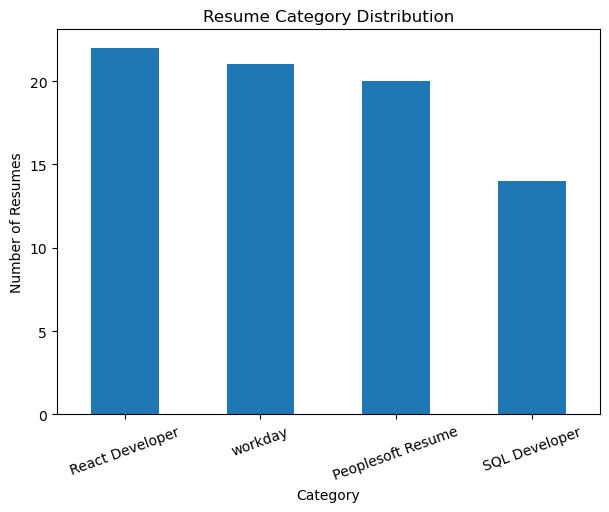

In [33]:
plt.figure(figsize=(7,5))

resume_df["Category"].value_counts().plot(kind="bar")

plt.title("Resume Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Resumes")
plt.xticks(rotation=20)

plt.show()


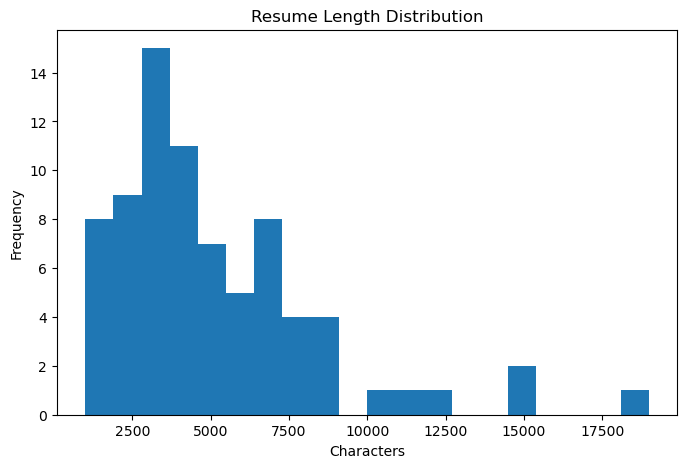

In [34]:
plt.figure(figsize=(8,5))

plt.hist(resume_df["Resume_Length"], bins=20)

plt.title("Resume Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Frequency")

plt.show()


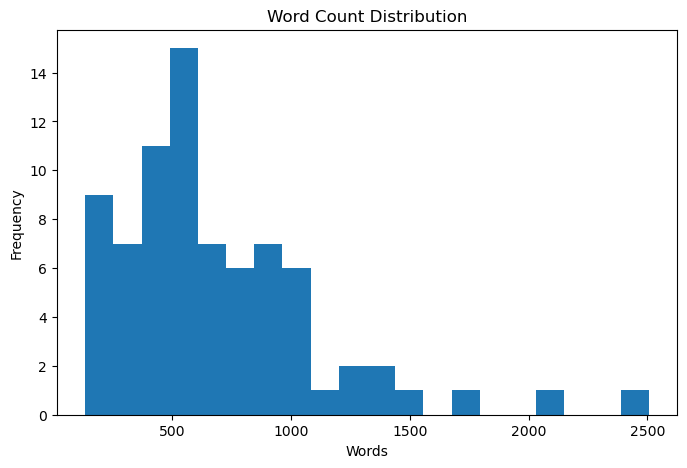

In [35]:
plt.figure(figsize=(8,5))

plt.hist(resume_df["Word_Count"], bins=20)

plt.title("Word Count Distribution")
plt.xlabel("Words")
plt.ylabel("Frequency")

plt.show()


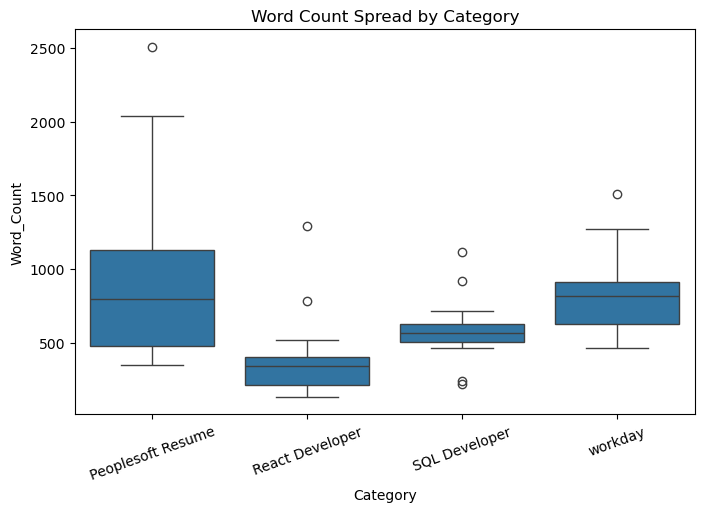

In [36]:
# Boxplot shows spread and outliers per category, not just the mean
plt.figure(figsize=(8,5))

sns.boxplot(data=resume_df, x="Category", y="Word_Count")

plt.title("Word Count Spread by Category")
plt.xticks(rotation=20)

plt.show()


In [37]:
avg_length = resume_df.groupby("Category")["Word_Count"].mean()

avg_length


Category
Peoplesoft Resume    935.200000
React Developer      379.863636
SQL Developer        585.000000
workday              825.285714
Name: Word_Count, dtype: float64

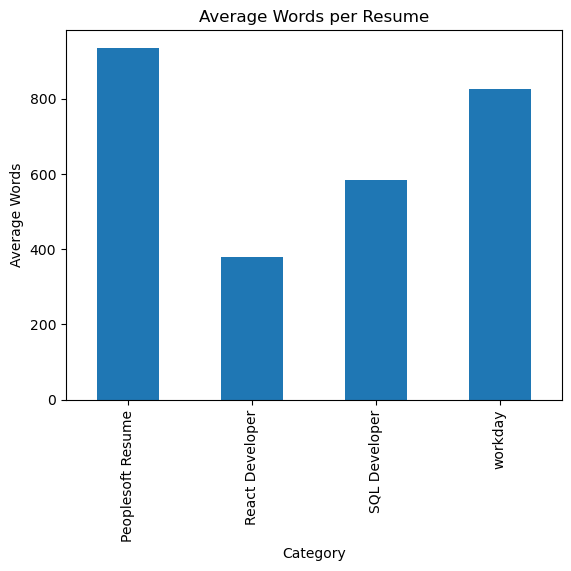

In [38]:
avg_length.plot(kind="bar")

plt.title("Average Words per Resume")
plt.ylabel("Average Words")

plt.show()


In [39]:
# Sanity check: flag unusually short resumes (possible extraction issues rather than
# genuinely short resumes) so they can be manually spot-checked.
resume_df.sort_values("Word_Count").head(5)[["File_Name", "Category", "Word_Count"]]


,File_Name,Category,Word_Count
48,React Developer_Thirupathiamma.docx,React Developer,133
2,Reactjs Developer_kambala sai surendra_Musquar...,React Developer,172
8,Reactjs Developer_Shaik Abdul Sharuk_Musquare ...,React Developer,182
50,Internship_Susovan Bag_Musquare Technologies.docx,React Developer,184
46,React Developer_Naveen sadhu.docx,React Developer,193


# Step 5: Text Preprocessing

The extracted resume text contains noise: URLs, email addresses, phone numbers, punctuation, digits, and common stopwords. Before feature extraction (TF-IDF) and model training, the text is cleaned and standardized to reduce that noise.


In [40]:
stop_words = set(stopwords.words("english"))

stemmer = PorterStemmer()


In [41]:
# Text cleaning is organized as a pipeline of small, named steps rather than one long
# function — each step does exactly one job, which makes it easy to reorder, disable, or
# unit-test individual steps later (e.g. "what if I skip stemming?").

def _strip_urls(text):
    return re.sub(r"http\S+|www\S+", " ", text)

def _strip_emails(text):
    return re.sub(r"\S+@\S+", " ", text)

def _strip_phone_numbers(text):
    # Matches common phone formats: +91 98765 43210, (080) 4567-8901, 9876543210, etc.
    return re.sub(r"\+?\d[\d\-\(\) ]{8,}\d", " ", text)

def _strip_non_ascii(text):
    # Resumes converted from legacy .doc files sometimes carry garbled/encoding-artifact
    # characters (smart quotes, bullet glyphs that didn't convert cleanly, etc.). Dropping
    # anything outside the standard ASCII range removes this noise before it reaches TF-IDF.
    return re.sub(r"[^\x00-\x7F]+", " ", text)

def _strip_digits(text):
    return re.sub(r"\d+", " ", text)

def _strip_punctuation(text):
    return text.translate(str.maketrans("", "", string.punctuation))

def _collapse_whitespace(text):
    return re.sub(r"\s+", " ", text).strip()

# Order matters: run whitespace-sensitive steps (URLs/emails/phones) before punctuation
# stripping removes the characters (like @ and .) those patterns rely on to match.
CLEANING_STEPS = [
    _strip_urls,
    _strip_emails,
    _strip_phone_numbers,
    _strip_non_ascii,
    _strip_digits,
    _strip_punctuation,
    _collapse_whitespace,
]

def preprocess_text(text):
    text = text.lower()

    for step in CLEANING_STEPS:
        text = step(text)

    tokens = [
        stemmer.stem(word)
        for word in text.split()
        if word not in stop_words
    ]

    return " ".join(tokens)


In [42]:
resume_df["Clean_Resume"] = resume_df["Resume"].apply(preprocess_text)


In [43]:
print("Original Resume\n")
print(resume_df["Resume"][0][:1000])

print("\n" + "="*80 + "\n")

print("Cleaned Resume\n")
print(resume_df["Clean_Resume"][0][:1000])


Original Resume







	

Profile Summary:										
     7+ years of experience in implementing, upgrading, and supporting PeopleSoft database administration including Human Capital Management (HCM), Financials, Campus Solutions and Portal IHUB
     Expertise in installation, configuration, setup, security and management of the PeopleSoft Internet Architecture PIA environment.
     In-depth experience in analysis, planning, development, and implementation stages, including load testing, quality assurance, and tuning.
     Gained extensive exposure in deploying PeopleSoft Environments.
     Experienced in Troubleshooting PeopleSoft Components.
     Skilled with the capability to analyse & interpret unique problems with a combination of training experience & logical thinking to find the right solutions

Core Competencies:											  

     PeopleSoft Implementation. 
     Troubleshooting	 PeopleSoft performance issues.                             
     Project /Data Migration        
 

In [44]:
resume_df.to_csv("Resume_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")


Cleaned dataset saved successfully.


In [45]:
resume_df.head()


,File_Name,Category,Resume,Extraction_Method,Resume_Length,Word_Count,Clean_Resume
0,Peoplesoft Admin_G Ananda Rayudu.docx,Peoplesoft Resume,\n\n\n\n\n\n\t\n\nProfile Summary:\t\t\t\t\t\t...,libreoffice (.docx fallback),8361,972,profil summari year experi implement upgrad su...
1,React JS Developer_Venkatalakshmi (1)-converte...,React Developer,Venkatalakshmi Pedireddy\nSoftware Developer\n...,python-docx (primary),2120,301,venkatalakshmi pedireddi softwar develop exper...
2,Reactjs Developer_kambala sai surendra_Musquar...,React Developer,KAMBALA SAI SURENDRA \n \n\tMandepeta \t \n ...,python-docx (primary),1568,172,kambala sai surendra mandepeta summari project...
3,Reactjs Developer_M Lokesh Babu_Musquare Techn...,React Developer,MAREEDU LOKESH BABU\nPROFESSIONAL OVERVIEW\n ...,python-docx (primary),2912,324,mareedu lokesh babu profession overview around...
4,Reactjs Developer_MD Khizaruddin Rauf _Musquar...,React Developer,MD KHIZARUDDIN RAUF \n \t EXPERIENCE \n \n...,python-docx (primary),3172,380,md khizaruddin rauf experi current work pickup...


In [46]:
# final_df keeps only the columns needed for modeling. .copy() makes it an
# independent DataFrame (not just a view into resume_df), since new columns
# get added to it in Step 7.
final_df = resume_df[["File_Name", "Category", "Clean_Resume"]].copy()

final_df.head()


,File_Name,Category,Clean_Resume
0,Peoplesoft Admin_G Ananda Rayudu.docx,Peoplesoft Resume,profil summari year experi implement upgrad su...
1,React JS Developer_Venkatalakshmi (1)-converte...,React Developer,venkatalakshmi pedireddi softwar develop exper...
2,Reactjs Developer_kambala sai surendra_Musquar...,React Developer,kambala sai surendra mandepeta summari project...
3,Reactjs Developer_M Lokesh Babu_Musquare Techn...,React Developer,mareedu lokesh babu profession overview around...
4,Reactjs Developer_MD Khizaruddin Rauf _Musquar...,React Developer,md khizaruddin rauf experi current work pickup...


In [47]:
final_df.tail()

,File_Name,Category,Clean_Resume
72,Venkateswarlu B_Hexaware.doc,workday,venkateswarlub workday consult year experi yea...
73,React Developer_PavasGoswami.doc,React Developer,profil search opportun bring year experi softw...
74,React JS Developer_AnjaniPriyadarshini.doc,React Developer,curriculum vita anjani priyadarshini sr web de...
75,Hima Mendu_Hexaware.doc,workday,himamendu career object continu grow knowledg ...
76,Peoplesoft Finance_Arun Venu.doc,Peoplesoft Resume,arun venu experi summari experi year month mul...


In [48]:
final_df["Category"].value_counts()


Category
React Developer      22
workday              21
Peoplesoft Resume    20
SQL Developer        14
Name: count, dtype: int64

# Step 6: Near-Duplicate QA Check (TF-IDF Similarity)

The de-duplication above only removes *exact* text matches (after whitespace normalization). It's worth double-checking for resumes that are highly similar but not identical — e.g. the same resume with a couple of lines edited between versions. This step doesn't drop anything automatically; it just flags close pairs for a human to look at.


In [49]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

SIMILARITY_ALERT_THRESHOLD = 0.99

tfidf = TfidfVectorizer(stop_words="english", max_features=3000)
tfidf_matrix = tfidf.fit_transform(resume_df["Clean_Resume"])
similarity_matrix = cosine_similarity(tfidf_matrix)

# Only the upper triangle (excluding the diagonal) holds unique pairs — pulling indices this
# way avoids writing a manual nested loop over every (i, j) combination.
row_idx, col_idx = np.triu_indices_from(similarity_matrix, k=1)
pair_scores = similarity_matrix[row_idx, col_idx]

flagged = pair_scores >= SIMILARITY_ALERT_THRESHOLD

close_pairs = pd.DataFrame({
    "Resume_A": resume_df["File_Name"].values[row_idx[flagged]],
    "Resume_B": resume_df["File_Name"].values[col_idx[flagged]],
    "Category_A": resume_df["Category"].values[row_idx[flagged]],
    "Similarity": pair_scores[flagged],
}).sort_values("Similarity", ascending=False).reset_index(drop=True)

if close_pairs.empty:
    print(f"No resume pairs above the {SIMILARITY_ALERT_THRESHOLD:.0%} similarity threshold — "
          "de-duplication looks complete.")
else:
    print(f"{len(close_pairs)} pair(s) above {SIMILARITY_ALERT_THRESHOLD:.0%} similarity — worth a manual look:")

close_pairs


No resume pairs above the 99% similarity threshold — de-duplication looks complete.


,Resume_A,Resume_B,Category_A,Similarity


# Step 7: Modeling Preparation

Two things need to happen before this dataset is ready to hand to a classifier: the text category labels need to become numbers, and the data needs to be split into train/test sets in a way that keeps the class balance from Step 4 intact in both halves.


In [50]:
# Encode category labels as integers for modeling.
label_codes, label_names = pd.factorize(final_df["Category"])
final_df["Category_Code"] = label_codes

label_lookup = {name: code for code, name in enumerate(label_names)}
print("Category -> code mapping:")
for name, code in label_lookup.items():
    print(f"  {code}: {name}")


Category -> code mapping:
  0: Peoplesoft Resume
  1: React Developer
  2: SQL Developer
  3: workday


In [51]:
from sklearn.model_selection import train_test_split

TEST_FRACTION = 0.25
SPLIT_SEED = 7

X_train, X_test, y_train, y_test = train_test_split(
    final_df["Clean_Resume"],
    final_df["Category_Code"],
    test_size=TEST_FRACTION,
    random_state=SPLIT_SEED,
    stratify=final_df["Category_Code"],   # keeps each category's share the same in both splits
)

print(f"Train set: {X_train.shape[0]} resumes")
print(f"Test set:  {X_test.shape[0]} resumes")
print()
print("Train set class balance:")
print(y_train.value_counts(normalize=True).sort_index().round(3))
print()
print("Test set class balance:")
print(y_test.value_counts(normalize=True).sort_index().round(3))


Train set: 57 resumes
Test set:  20 resumes

Train set class balance:
Category_Code
0    0.263
1    0.281
2    0.175
3    0.281
Name: proportion, dtype: float64

Test set class balance:
Category_Code
0    0.25
1    0.30
2    0.20
3    0.25
Name: proportion, dtype: float64


# Step 8: Word Frequency by Category

Which words dominate each job category's resumes? This is a quick sanity check before modeling — the top words per category should obviously relate to that role (e.g. React resumes should be full of "react", "javascript", "component"). If they don't, that's a sign something upstream (extraction or category labeling) went wrong.


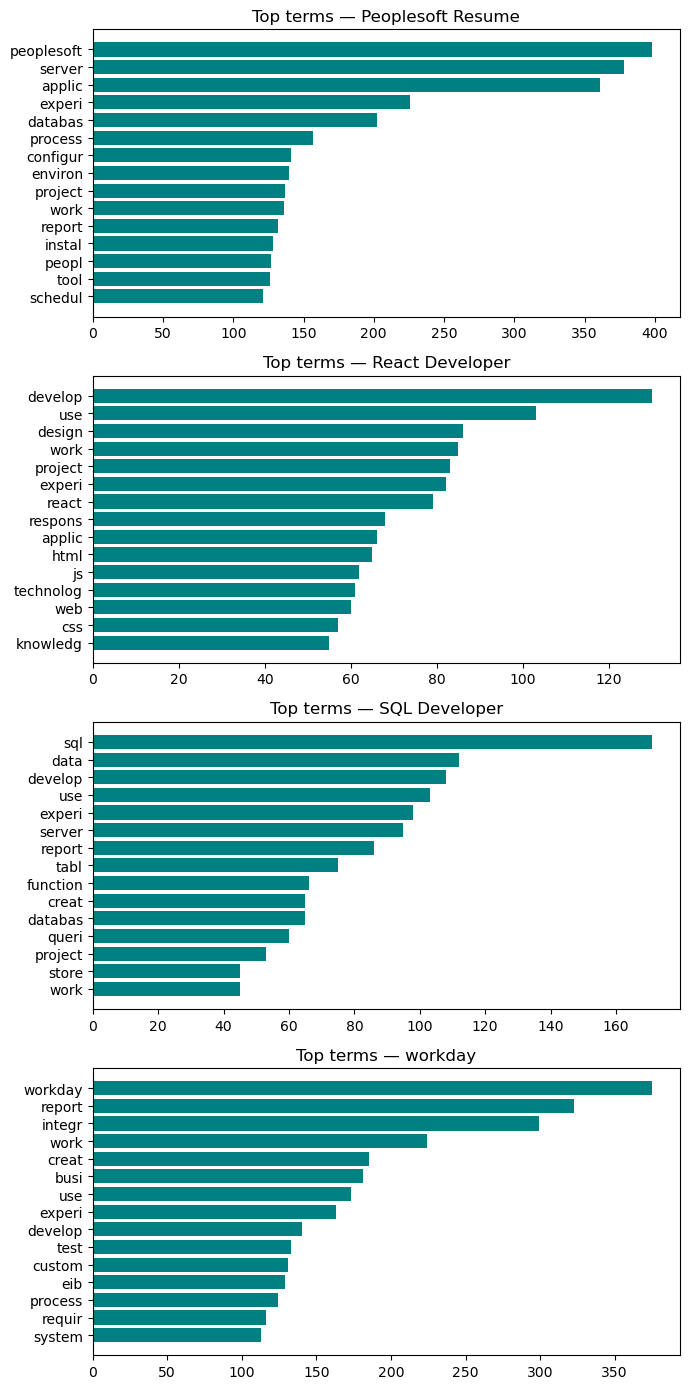

In [52]:
from nltk import FreqDist

def top_terms_for_category(category_name, n=15):
    category_text = " ".join(final_df.loc[final_df["Category"] == category_name, "Clean_Resume"])
    freq = FreqDist(category_text.split())
    return freq.most_common(n)

category_list = final_df["Category"].unique()

fig, axes = plt.subplots(nrows=len(category_list), ncols=1, figsize=(7, 3.5 * len(category_list)))

for ax, cat in zip(axes, category_list):
    top = top_terms_for_category(cat)
    words, counts = zip(*top)
    ax.barh(words, counts, color="teal")
    ax.invert_yaxis()
    ax.set_title(f"Top terms — {cat}")

plt.tight_layout()
plt.show()


# Step 9: Bigram Analysis

Single words only tell part of the story — two-word phrases ("machine learning", "react native") are often more distinctive of a category than either word alone.


In [53]:
from nltk.util import ngrams
from collections import Counter

def top_bigrams_for_category(category_name, n=10):
    category_text = " ".join(final_df.loc[final_df["Category"] == category_name, "Clean_Resume"])
    tokens = category_text.split()
    bigram_list = list(ngrams(tokens, 2))
    bigram_counts = Counter(bigram_list)
    return [(" ".join(pair), count) for pair, count in bigram_counts.most_common(n)]

for cat in category_list:
    print(f"\n=== Top bigrams: {cat} ===")
    for phrase, count in top_bigrams_for_category(cat):
        print(f"  {phrase}: {count}")



=== Top bigrams: Peoplesoft Resume ===
  applic server: 119
  process schedul: 100
  web server: 87
  server domain: 75
  peopl tool: 73
  schedul server: 56
  experi peoplesoft: 48
  server web: 47
  instal configur: 45
  chang assist: 45

=== Top bigrams: React Developer ===
  react js: 48
  html css: 44
  good knowledg: 21
  css javascript: 16
  use html: 15
  ui develop: 14
  year experi: 12
  project titl: 12
  web applic: 12
  softwar develop: 11

=== Top bigrams: SQL Developer ===
  sql server: 91
  store procedur: 35
  power bi: 33
  ms sql: 16
  use sql: 16
  design develop: 16
  good knowledg: 16
  till date: 15
  good experi: 13
  ssi packag: 12

=== Top bigrams: workday ===
  busi process: 80
  custom report: 75
  calcul field: 72
  core connector: 69
  workday studio: 64
  workday hcm: 55
  report writer: 46
  web servic: 38
  document transform: 36
  integr use: 34


# Step 10: Class Separability (t-SNE)

Do the categories form visually distinct clusters once resumes are vectorized? This is a rough, qualitative check of whether the classes are separable at all — not a substitute for a real evaluation metric later. TF-IDF features are reduced to 50 dimensions with SVD first, then to 2D with t-SNE — going straight from raw TF-IDF (often 1000+ dimensions) into t-SNE tends to produce noisier, less stable layouts than pre-reducing with SVD first.


SVD explained variance (50 components): 88.6%


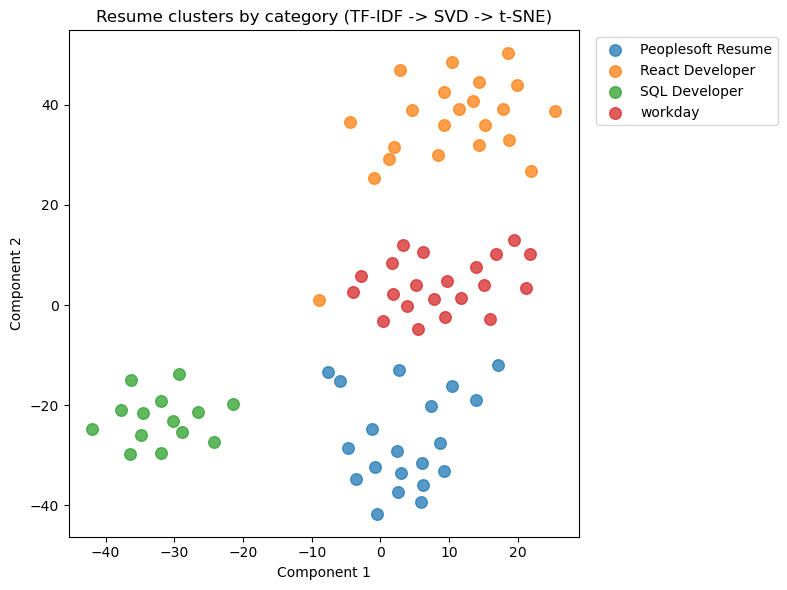

In [54]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE

tfidf_vectorizer = TfidfVectorizer(max_features=1500, stop_words="english")
tfidf_features = tfidf_vectorizer.fit_transform(final_df["Clean_Resume"])

svd = TruncatedSVD(n_components=50, random_state=SPLIT_SEED)
reduced_features = svd.fit_transform(tfidf_features)
print(f"SVD explained variance (50 components): {svd.explained_variance_ratio_.sum():.1%}")

tsne = TSNE(n_components=2, random_state=SPLIT_SEED, perplexity=12, init="pca")
coords_2d = tsne.fit_transform(reduced_features)

plt.figure(figsize=(8, 6))
for cat in category_list:
    mask = (final_df["Category"] == cat).values
    plt.scatter(coords_2d[mask, 0], coords_2d[mask, 1], label=cat, s=70, alpha=0.75)

plt.title("Resume clusters by category (TF-IDF -> SVD -> t-SNE)")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [55]:
total_duplicate_groups = sum(1 for records in grouped_resumes.values() if len(records) > 1) + \
                          content_dupes["_dedup_key"].nunique() if 'content_dupes' in dir() else None

print(f"Filename-based duplicate groups: {sum(1 for r in grouped_resumes.values() if len(r) > 1)}")
print(f"Content-based duplicate groups: {resume_df.duplicated(subset='Resume').sum()}")

Filename-based duplicate groups: 1
Content-based duplicate groups: 0


In [56]:
print(f"Total duplicate resumes removed: 80 - {resume_df.shape[0]} = {80 - resume_df.shape[0]}")

Total duplicate resumes removed: 80 - 77 = 3


In [57]:
all_filenames = set(r["File_Name"] for r in resume_data)
kept_filenames = set(resume_df["File_Name"])
removed_duplicates = all_filenames - kept_filenames

print("Removed as duplicates:")
for f in removed_duplicates:
    print(" ", f)

print("\nFailed / corrupted files:")
for f in failed_files:
    print(" ", f["File_Name"], "-", f["Reason"])

Removed as duplicates:
  React Dev_Krishna Kanth.docx
  Peoplesoft Admin_G Ananda Rayudu.doc
  Reactjs Developer_M Lokesh.docx

Failed / corrupted files:


# Step 11: TF-IDF Vectorization

Models can't work with raw text, so `Clean_Resume` needs to become numeric features. TF-IDF (Term Frequency - Inverse Document Frequency) scores each word by how often it appears in a resume relative to how common it is across all resumes — this gives more weight to words that are distinctive of a category (e.g. "kubernetes") and less weight to generic words that show up everywhere.

The vectorizer is fit only on the training set and then used to transform the test set — fitting on the full dataset first would leak information from the test set into training.


In [58]:
from sklearn.feature_extraction.text import TfidfVectorizer

MAX_FEATURES = 3000

vectorizer = TfidfVectorizer(stop_words="english", max_features=MAX_FEATURES)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print(f"Vocabulary size: {len(vectorizer.vocabulary_)}")
print(f"Train feature matrix: {X_train_vec.shape}")
print(f"Test feature matrix:  {X_test_vec.shape}")


Vocabulary size: 3000
Train feature matrix: (57, 3000)
Test feature matrix:  (20, 3000)


# Step 12: Train and Compare Models

With only 77 resumes across 4 categories, a handful of classic text-classification models are more appropriate here than a deep learning approach — there isn't enough data for a large neural network to learn from without overfitting (though a small MLP is included below as a comparison point). Ten models spanning a few different families are trained and compared:

- **Naive Bayes** — Multinomial and Complement variants (Complement NB is designed to handle class imbalance better, which is relevant here since categories range from 14 to 22 resumes)
- **Linear models** — Logistic Regression, SGD Classifier (hinge loss, i.e. a linearly-trained SVM), and Linear SVM
- **Tree-based ensembles** — Random Forest, Extra Trees, Gradient Boosting
- **Instance-based** — K-Nearest Neighbors
- **Neural network** — a small Multi-Layer Perceptron

Macro-F1 (not plain accuracy) is used to rank models, since it treats every category equally regardless of how many resumes it has.


In [59]:
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

candidate_models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Complement Naive Bayes": ComplementNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SPLIT_SEED),
    "SGD Classifier (hinge loss)": SGDClassifier(loss="hinge", random_state=SPLIT_SEED),
    "Linear SVM": LinearSVC(random_state=SPLIT_SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SPLIT_SEED),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=SPLIT_SEED),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SPLIT_SEED),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "MLP (Neural Network)": MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=SPLIT_SEED),
}

model_results = []

for name, model in candidate_models.items():
    model.fit(X_train_vec, y_train)
    preds = model.predict(X_test_vec)

    model_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Macro_F1": f1_score(y_test, preds, average="macro"),
    })

model_results_df = pd.DataFrame(model_results).sort_values("Macro_F1", ascending=False).reset_index(drop=True)
model_results_df


,Model,Accuracy,Macro_F1
0,Complement Naive Bayes,1.00,1.000000
1,Logistic Regression,1.00,1.000000
2,SGD Classifier (hinge loss),1.00,1.000000
3,Linear SVM,1.00,1.000000
4,Random Forest,1.00,1.000000
5,Extra Trees,1.00,1.000000
6,K-Nearest Neighbors,1.00,1.000000
7,MLP (Neural Network),1.00,1.000000
8,Gradient Boosting,0.95,0.949495
9,Multinomial Naive Bayes,0.95,0.941558


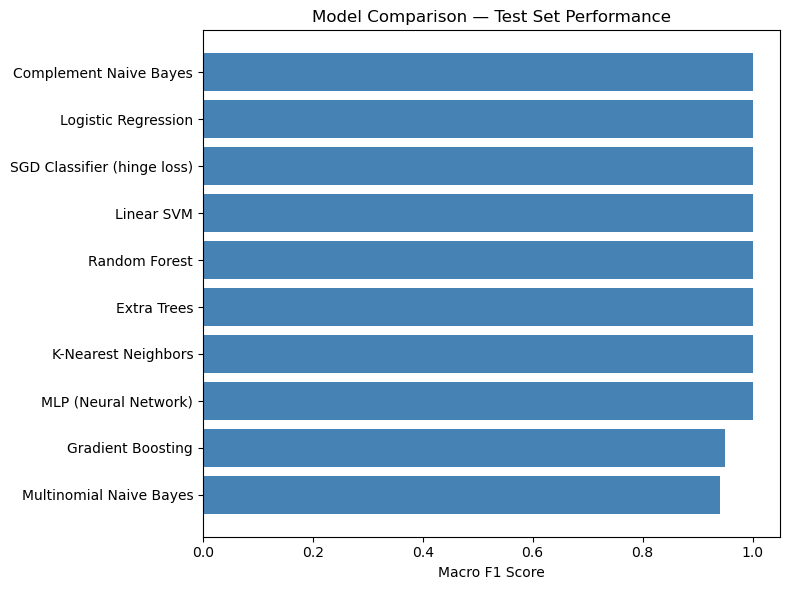

In [60]:
plt.figure(figsize=(8, 6))
plt.barh(model_results_df["Model"], model_results_df["Macro_F1"], color="steelblue")
plt.xlabel("Macro F1 Score")
plt.title("Model Comparison — Test Set Performance")
plt.xlim(0, 1.05)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


# Step 13: Cross-Validation

The test set above is only 20 resumes — small enough that a single train/test split could get lucky or unlucky depending on which resumes happened to land in the test set. 5-fold stratified cross-validation gives a steadier estimate by training and testing on 5 different splits of the full dataset and averaging the result.


In [61]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SPLIT_SEED)

cv_results = []

for name, model in candidate_models.items():
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", max_features=MAX_FEATURES)),
        ("clf", model),
    ])
    scores = cross_val_score(
        pipeline, final_df["Clean_Resume"], final_df["Category_Code"],
        cv=cv, scoring="f1_macro"
    )
    cv_results.append({
        "Model": name,
        "CV_Macro_F1_Mean": scores.mean(),
        "CV_Macro_F1_Std": scores.std(),
    })

cv_results_df = pd.DataFrame(cv_results).sort_values("CV_Macro_F1_Mean", ascending=False).reset_index(drop=True)
cv_results_df


,Model,CV_Macro_F1_Mean,CV_Macro_F1_Std
0,Linear SVM,1.000000,0.000000
1,K-Nearest Neighbors,0.989899,0.020202
2,Extra Trees,0.984444,0.031111
3,Complement Naive Bayes,0.974343,0.032585
4,SGD Classifier (hinge loss),0.974343,0.032585
5,Logistic Regression,0.972756,0.033922
6,MLP (Neural Network),0.972756,0.033922
7,Random Forest,0.971746,0.034898
8,Multinomial Naive Bayes,0.943232,0.030286
9,Gradient Boosting,0.927835,0.067128


In [62]:
# Sanity check: does the CV-best model also look best on the actual held-out test set?
# With a dataset this small, cross-validation and a single test set can disagree — a model
# can get lucky across the 5 CV folds without that holding up on this specific test split.
cv_best = cv_results_df.loc[0, "Model"]
test_best = model_results_df.loc[0, "Model"]

cv_best_test_f1 = model_results_df.loc[model_results_df["Model"] == cv_best, "Macro_F1"].values[0]

print(f"CV picks:   {cv_best} (CV macro-F1: {cv_results_df.loc[0, 'CV_Macro_F1_Mean']:.3f})")
print(f"Test picks: {test_best} (test macro-F1: {model_results_df.loc[0, 'Macro_F1']:.3f})")
print(f"\n{cv_best}'s actual score on this test set: {cv_best_test_f1:.3f}")

if cv_best != test_best:
    print("\nThese disagree. With only 77 resumes, this is expected sometimes — a model can \n"
          "score well by chance across small CV folds without that holding up on one specific \n"
          "test split. Worth reporting both rather than picking whichever number looks best.")


CV picks:   Linear SVM (CV macro-F1: 1.000)
Test picks: Complement Naive Bayes (test macro-F1: 1.000)

Linear SVM's actual score on this test set: 1.000

These disagree. With only 77 resumes, this is expected sometimes — a model can 
score well by chance across small CV folds without that holding up on one specific 
test split. Worth reporting both rather than picking whichever number looks best.


# Step 14: Detailed Evaluation of the Best Model

The top-ranked model from cross-validation is evaluated in more detail on the held-out test set: a full classification report (precision/recall/F1 per category) and a confusion matrix, which shows exactly which categories get confused with each other, not just an overall score.


In [63]:
from sklearn.metrics import classification_report, confusion_matrix

BEST_MODEL_NAME = cv_results_df.loc[0, "Model"]
best_model = candidate_models[BEST_MODEL_NAME]

best_model.fit(X_train_vec, y_train)
best_preds = best_model.predict(X_test_vec)

print(f"Best model (by cross-validated Macro F1): {BEST_MODEL_NAME}\n")
print(classification_report(y_test, best_preds, target_names=label_names))


Best model (by cross-validated Macro F1): Linear SVM

                   precision    recall  f1-score   support

Peoplesoft Resume       1.00      1.00      1.00         5
  React Developer       1.00      1.00      1.00         6
    SQL Developer       1.00      1.00      1.00         4
          workday       1.00      1.00      1.00         5

         accuracy                           1.00        20
        macro avg       1.00      1.00      1.00        20
     weighted avg       1.00      1.00      1.00        20



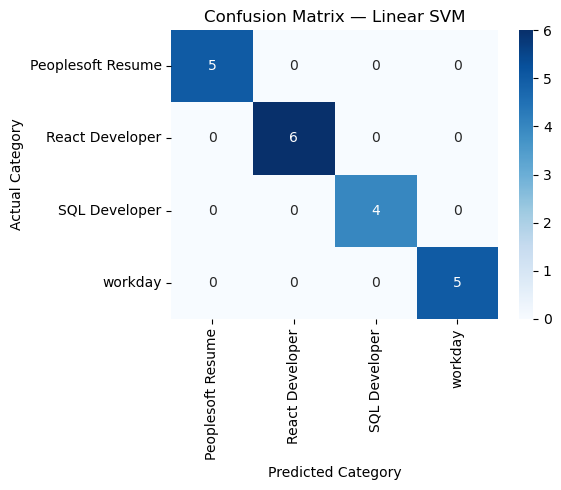

In [64]:
cm = confusion_matrix(y_test, best_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_names, yticklabels=label_names)
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title(f"Confusion Matrix — {BEST_MODEL_NAME}")
plt.tight_layout()
plt.show()


# Step 15: Save the Model

The trained model and the TF-IDF vectorizer are saved together — the vectorizer is needed at prediction time to turn new resume text into the same feature space the model was trained on.


In [65]:
import pickle

with open("resume_classifier.pkl", "wb") as f:
    pickle.dump({
        "model": best_model,
        "vectorizer": vectorizer,
        "label_names": label_names,
    }, f)

print(f"Saved resume_classifier.pkl ({BEST_MODEL_NAME} + TF-IDF vectorizer)")


Saved resume_classifier.pkl (Linear SVM + TF-IDF vectorizer)


In [66]:
# Quick sanity check: load it back and classify a new piece of resume text
with open("resume_classifier.pkl", "rb") as f:
    loaded = pickle.load(f)

sample_text = "react javascript redux hooks frontend developer component state management"
sample_vec = loaded["vectorizer"].transform([sample_text])
predicted_code = loaded["model"].predict(sample_vec)[0]

print("Sample text predicted category:", loaded["label_names"][predicted_code])


Sample text predicted category: React Developer


---
## Summary

- 80 raw resume files across 5 folders, normalized into 4 job categories (`Peoplesoft`
  and `Peoplesoft Resume` folders represent the same category and are merged).
- Text extracted from every file using pdfplumber (`.pdf`), python-docx (`.docx`, with
  a LibreOffice-based fallback for files that don't open normally), and LibreOffice
  headless conversion (`.doc`).
- Duplicate resumes removed in two passes: filename-based (same resume saved as both
  `.doc` and `.docx`) and content-based (same resume saved under a different filename
  entirely, matched after whitespace normalization).
- **Final cleaned dataset: 77 resumes.**
- A TF-IDF cosine-similarity check flags any near-duplicate resumes that survive exact
  matching but are still highly similar, for manual review.
- Categories encoded and split into stratified train/test sets.
- EDA covers class distribution, resume length, per-category word frequency, bigrams,
  and a t-SNE view of class separability in TF-IDF space.
- Resume text vectorized with TF-IDF, then 10 candidate models trained and compared
  across several families (Naive Bayes, linear models, tree ensembles, KNN, a small
  neural network) using macro-F1 to account for class imbalance across the 4 categories.
- 5-fold stratified cross-validation used alongside the single train/test split, since
  the test set alone (20 resumes) is too small to fully trust on its own. A sanity check
  compares the CV-best and test-best models and flags it if they disagree.
- Best-performing model evaluated in detail (classification report + confusion matrix)
  and saved to `resume_classifier.pkl` along with its TF-IDF vectorizer, ready for the
  Streamlit app to load and classify new resume text.
